# Week 3 Bonus · Preattentive pop-out experiment

Four panels use the same 12×18 digit grid and the same nine target 3s: no pop-out channel, color only, size only, and redundant color plus shape. The final timing analysis requires real observations from five classmates; the notebook prepares randomized orders and a data-entry template without inventing results.

Saved stimulus panels: d:\7_Semester\data-visualization\week3\assignments\popout_panels.png


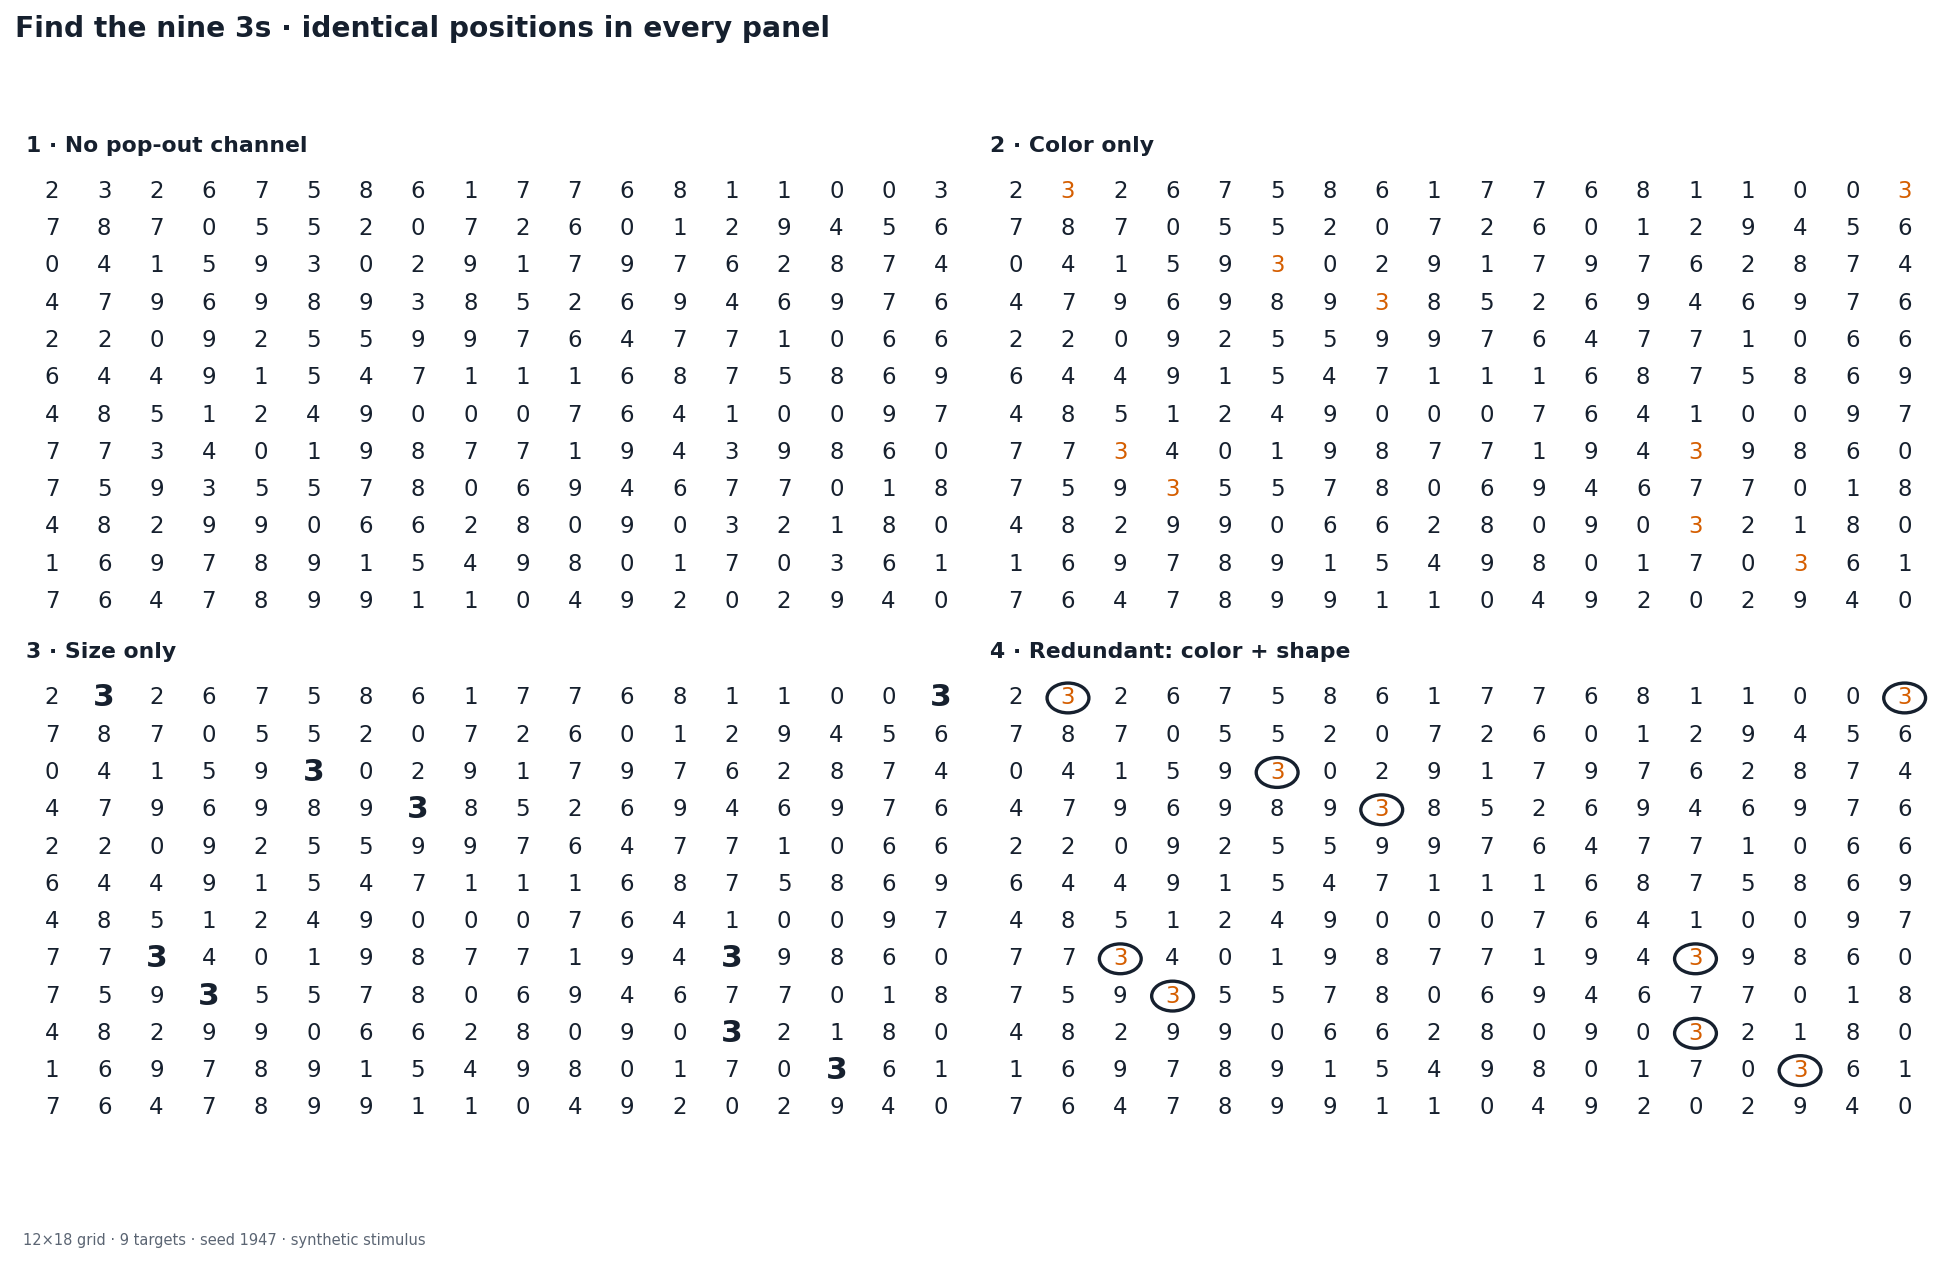

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WEEK3_DIR = next(
    path for path in (Path.cwd(), Path.cwd() / "week3", Path.cwd().parent / "week3")
    if (path / "assignments" / "vizlib.py").is_file()
)
ASSIGNMENTS_DIR = WEEK3_DIR / "assignments"
sys.path.insert(0, str(ASSIGNMENTS_DIR))
from vizlib import PALETTE, save_fig, style_defaults

style_defaults()
ROWS, COLS = 12, 18
TARGET = "3"
N_TARGETS = 9
SEED = 1947


def make_grid(seed=SEED):
    rng = np.random.default_rng(seed)
    alternatives = [digit for digit in "0123456789" if digit != TARGET]
    grid = np.array(
        [[rng.choice(alternatives) for _ in range(COLS)] for _ in range(ROWS)],
        dtype=object,
    )
    target_positions = rng.choice(ROWS * COLS, size=N_TARGETS, replace=False)
    for position in target_positions:
        grid[position // COLS, position % COLS] = TARGET
    return grid


def draw_panel(ax, grid, title, color=False, size=False, shape=False):
    ax.set_xlim(-0.5, COLS - 0.5)
    ax.set_ylim(-0.5, ROWS - 0.5)
    ax.invert_yaxis()
    ax.axis("off")
    ax.set_title(title, fontsize=10.5, loc="left")
    for row in range(ROWS):
        for column in range(COLS):
            digit = grid[row, column]
            target = digit == TARGET
            if shape and target:
                ax.add_patch(
                    plt.Circle(
                        (column, row), 0.40, fill=False,
                        edgecolor=PALETTE["ink"], linewidth=1.6,
                    )
                )
            ax.text(
                column,
                row,
                digit,
                ha="center",
                va="center",
                fontsize=15 if size and target else 11,
                fontweight="bold" if size and target else "normal",
                color=PALETTE["highlight"] if color and target else PALETTE["ink"],
            )


grid = make_grid()
assert int(np.count_nonzero(grid == TARGET)) == N_TARGETS
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
draw_panel(axes[0, 0], grid, "1 · No pop-out channel")
draw_panel(axes[0, 1], grid, "2 · Color only", color=True)
draw_panel(axes[1, 0], grid, "3 · Size only", size=True)
draw_panel(axes[1, 1], grid, "4 · Redundant: color + shape", color=True, shape=True)
fig.suptitle("Find the nine 3s · identical positions in every panel", x=0.006, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0.035, 1, 0.94])
panel_path = ASSIGNMENTS_DIR / "popout_panels.png"
save_fig(fig, panel_path, f"{ROWS}×{COLS} grid · {N_TARGETS} targets · seed {SEED} · synthetic stimulus")
print(f"Saved stimulus panels: {panel_path}")
plt.show()
plt.close(fig)

## Five-person timing protocol

Use one participant slot per classmate. Show only the assigned panel, start timing when it appears, and stop when the person finishes counting. Record elapsed seconds and the number counted (0–9); do not reveal the answer between panels. The code generates a distinct random order for each slot with a fixed, reported seed so the session can be reproduced.

In [2]:
ORDER_SEED = 1948
PARTICIPANTS = [f"P{number}" for number in range(1, 6)]
PANEL_NUMBERS = np.arange(1, 5)
order_rng = np.random.default_rng(ORDER_SEED)
orders = []
seen_orders = set()
while len(orders) < len(PARTICIPANTS):
    candidate = tuple(int(panel) for panel in order_rng.permutation(PANEL_NUMBERS))
    if candidate not in seen_orders:
        orders.append(candidate)
        seen_orders.add(candidate)

presentation_orders = pd.DataFrame(
    orders,
    index=PARTICIPANTS,
    columns=["Round 1", "Round 2", "Round 3", "Round 4"],
)
presentation_orders.index.name = "Participant slot"
print(f"Distinct panel orders (NumPy seed {ORDER_SEED}):")
display(presentation_orders)

timing_template = pd.DataFrame(
    [
        {"participant_slot": participant, "panel": panel, "seconds": pd.NA, "counted": pd.NA}
        for participant, order in zip(PARTICIPANTS, orders)
        for panel in order
    ]
)
print("Enter actual elapsed seconds and count (0–9) for each displayed trial:")
display(timing_template)

Distinct panel orders (NumPy seed 1948):


,Round 1,Round 2,Round 3,Round 4
Participant slot,,,,
P1,1,4,3,2
P2,4,1,2,3
P3,4,2,3,1
P4,3,1,4,2
P5,3,4,1,2


Enter actual elapsed seconds and count (0–9) for each displayed trial:


,participant_slot,panel,seconds,counted
0,P1,1,<NA>,<NA>
1,P1,4,<NA>,<NA>
2,P1,3,<NA>,<NA>
3,P1,2,<NA>,<NA>
4,P2,4,<NA>,<NA>
5,P2,1,<NA>,<NA>
6,P2,2,<NA>,<NA>
7,P2,3,<NA>,<NA>
8,P3,4,<NA>,<NA>
9,P3,2,<NA>,<NA>


## Record observations and analyze them

After timing the five classmates, replace the missing `seconds` and `counted` entries in the next code cell with observations. Keep incorrect counts in the data; the chart shows accuracy beside speed instead of silently dropping trials.

In [3]:
# Replace the missing values below with the five classmates' recorded trials.
timing_data = timing_template.copy()
print("Timing data-entry table (seconds and counted targets):")
display(timing_data)

Timing data-entry table (seconds and counted targets):


,participant_slot,panel,seconds,counted
0,P1,1,<NA>,<NA>
1,P1,4,<NA>,<NA>
2,P1,3,<NA>,<NA>
3,P1,2,<NA>,<NA>
4,P2,4,<NA>,<NA>
5,P2,1,<NA>,<NA>
6,P2,2,<NA>,<NA>
7,P2,3,<NA>,<NA>
8,P3,4,<NA>,<NA>
9,P3,2,<NA>,<NA>


Replace each `pd.NA` in `timing_data` with the actual elapsed seconds and count for that participant-panel trial. The next cell checks all 20 trials and valid counts before producing the chart or the three-sentence result; it intentionally reports no winner while the table is blank.

In [4]:
panel_names = {
    1: "No channel",
    2: "Color",
    3: "Size",
    4: "Color + shape",
}
required_columns = {"participant_slot", "panel", "seconds", "counted"}
missing_columns = required_columns - set(timing_data.columns)
if missing_columns:
    raise ValueError(f"Timing data is missing columns: {sorted(missing_columns)}")

completed_trials = timing_data.dropna(subset=["seconds", "counted"]).copy()
if len(completed_trials) != 20:
    print(
        f"No timing results yet: {len(completed_trials)} of 20 trials are complete. "
        "Enter all five classmates' observed seconds and counts, then rerun this cell."
    )
else:
    completed_trials["seconds"] = pd.to_numeric(completed_trials["seconds"])
    completed_trials["counted"] = pd.to_numeric(completed_trials["counted"]).astype(int)
    assert set(completed_trials["panel"]) == {1, 2, 3, 4}
    assert completed_trials.groupby("participant_slot").size().eq(4).all()
    assert completed_trials["seconds"].gt(0).all()
    assert completed_trials["counted"].between(0, N_TARGETS).all()

    mean_seconds = completed_trials.groupby("panel")["seconds"].mean().reindex([1, 2, 3, 4])
    correct_counts = completed_trials.assign(correct=completed_trials["counted"].eq(N_TARGETS)).groupby("panel")["correct"].sum().reindex([1, 2, 3, 4])
    accuracy = 100 * correct_counts / len(PARTICIPANTS)
    fastest_panel = int(mean_seconds.idxmin())
    slowest_panel = int(mean_seconds.idxmax())
    redundant_difference = float(mean_seconds.loc[4] - mean_seconds.loc[2])

    fastest_sentence = f"Panel {fastest_panel} ({panel_names[fastest_panel]}) was fastest at {mean_seconds.loc[fastest_panel]:.2f} seconds on average."
    slowest_sentence = f"Panel {slowest_panel} ({panel_names[slowest_panel]}) was slowest at {mean_seconds.loc[slowest_panel]:.2f} seconds on average."
    if redundant_difference > 0:
        redundancy_sentence = f"Panel 4 took {redundant_difference:.2f} seconds longer on average than panel 2; accuracy was {accuracy.loc[4]:.0f}% versus {accuracy.loc[2]:.0f}%."
    elif redundant_difference < 0:
        redundancy_sentence = f"Panel 4 took {-redundant_difference:.2f} seconds less on average than panel 2; accuracy was {accuracy.loc[4]:.0f}% versus {accuracy.loc[2]:.0f}%."
    else:
        redundancy_sentence = f"Panels 2 and 4 had the same mean time; accuracy was {accuracy.loc[4]:.0f}% versus {accuracy.loc[2]:.0f}%."
    print(fastest_sentence)
    print(slowest_sentence)
    print(redundancy_sentence)

    plot_data = completed_trials.copy()
    plot_data["correct"] = plot_data["counted"].eq(N_TARGETS)
    summary = mean_seconds.reindex([1, 2, 3, 4])
    fig, ax = plt.subplots(figsize=(9, 5.2))
    x_positions = np.arange(1, 5)
    ax.bar(x_positions, summary.values, color=PALETTE["muted"], alpha=0.35, edgecolor=PALETTE["ink_soft"], width=0.65, zorder=1)
    jitter_rng = np.random.default_rng(1949)
    for panel_number in range(1, 5):
        panel_trials = plot_data.loc[plot_data["panel"] == panel_number]
        x_jitter = panel_number + jitter_rng.uniform(-0.12, 0.12, size=len(panel_trials))
        for is_correct, marker, color, label in [
            (True, "o", PALETTE["series"][0], "Counted all 9 correctly"),
            (False, "X", PALETTE["highlight"], "Count was incorrect"),
        ]:
            selected = panel_trials["correct"] == is_correct
            if selected.any():
                ax.scatter(
                    x_jitter[selected], panel_trials.loc[selected, "seconds"],
                    marker=marker, color=color, s=55, label=label if panel_number == 1 else None,
                    zorder=3,
                )
    ax.set_xticks(x_positions, [panel_names[number] for number in x_positions])
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Search time (seconds)")
    ax.set_xlabel("Preattentive channel")
    ax.set_title(f"Panel {fastest_panel} was fastest; panel {slowest_panel} was slowest")
    ax.legend(title="Accuracy")
    source_note = f"n=5 classmates; 20 trials; distinct random order per participant (NumPy seed {ORDER_SEED}); individual times shown."
    fig.text(0.01, -0.03, source_note, fontsize=8, color=PALETTE["ink_soft"], ha="left")
    fig.tight_layout()
    experiment_chart_path = ASSIGNMENTS_DIR / "popout_experiment.png"
    fig.savefig(experiment_chart_path, dpi=300, bbox_inches="tight")
    print(f"Saved timing chart: {experiment_chart_path}")
    plt.show()
    plt.close(fig)

No timing results yet: 0 of 20 trials are complete. Enter all five classmates' observed seconds and counts, then rerun this cell.
